# Stage 4: Do defence and tracking features help? (Kaggle NBA Shot Logs 2014-15)

**Question (RQ1).** The main model knows where and how a shot was taken and what happened before it, but not how
closely it was defended. Per-shot tracking data (closest defender distance, shot clock, dribbles, touch time) were public
only for part of the 2014-15 season (Kaggle "NBA Shot Logs", matched to our shots in Stage 2). On these 126,838 shots we
measure how much such features add, i.e. how much the main model loses by not having them.

**Design.** Same model class (LightGBM, default parameters, no tuning) with four feature sets on the same shots:
- **A** shot features (location, shot type, time) = main model without context,
- **B** A + play-by-play context,
- **C** A + tracking (defender distance, shot clock, touch time, dribbles, catch-and-shoot),
- **D** A + context + tracking.

**Validation.** Time split inside the season, walk-forward by month: test December, January and February-March, each
time training on all earlier games (October-November only train). The identity of the defender is not used
(for the same reason as the identity of the shooter). Differences are tested with the paired game-level bootstrap.

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from xpts.gbm import CONTEXT_FEATURES, GBM_FEATURES, GBMModel, gbm_matrix
from xpts.metrics import evaluate, paired_bootstrap

FIG_DIR = Path("../reports/figures")
KEY = ["GAME_ID", "GAME_EVENT_ID"]
TRACKING_FEATURES = ["close_def_dist", "shot_clock", "shot_clock_off", "touch_time", "dribbles", "is_catch_shoot"]

df = pd.read_parquet("../data/processed/kaggle_features.parquet")
df = df.merge(pd.read_parquet("../data/processed/shots_context.parquet"), on=KEY, how="left", validate="1:1")
df = df.sort_values(["GAME_DATE", "GAME_ID", "GAME_EVENT_ID"]).reset_index(drop=True)
y = df["SHOT_MADE_FLAG"]
df["month"] = df["GAME_DATE"].str[:6].replace({"201410": "201411", "201503": "201502"})  # Oct -> Nov, Mar -> Feb
print(f"shots: {len(df):,}, games: {df['GAME_ID'].nunique():,}, {df['GAME_DATE'].min()} to {df['GAME_DATE'].max()}")
display(df.groupby("month").agg(shots=("SHOT_MADE_FLAG", "size"), games=("GAME_ID", "nunique"), fg_pct=("SHOT_MADE_FLAG", "mean")).round(3))

shots: 126,838, games: 904, 20141028 to 20150304


,shots,games,fg_pct
month,,,
201411,33869,247,0.456
201412,34126,232,0.456
201501,33000,231,0.449
201502,25843,194,0.445


## 1. Four feature sets, walk-forward by month

In [2]:
feature_sets = {"A_shot": GBM_FEATURES,
                "B_context": GBM_FEATURES + CONTEXT_FEATURES,
                "C_tracking": GBM_FEATURES + TRACKING_FEATURES,
                "D_context_tracking": GBM_FEATURES + CONTEXT_FEATURES + TRACKING_FEATURES}
months = sorted(df["month"].unique())
oos = df[KEY + ["month"]].assign(y=y)
rows = []
for name, feats in feature_sets.items():
    for i in range(1, len(months)):
        tr, te = df["month"].isin(months[:i]).to_numpy(), (df["month"] == months[i]).to_numpy()
        p = GBMModel(features=feats).fit(df[tr], y[tr]).predict_proba(df[te])[:, 1]
        oos.loc[te, name] = p
        rows.append({"model": name, "month": months[i], "n_train": int(tr.sum()), **evaluate(y[te], p)})

res = pd.DataFrame(rows)
oos = oos.dropna(subset=["A_shot"])
# pooled over all test shots (months have different sizes)
display(pd.DataFrame({m: evaluate(oos["y"], oos[m]) for m in feature_sets}).T.round(4))
display(res.pivot(index="month", columns="model", values="log_loss")[list(feature_sets)].round(4))

,n,log_loss,brier,auc
A_shot,92969.0,0.6393,0.2247,0.6626
B_context,92969.0,0.6360,0.2233,0.6667
C_tracking,92969.0,0.6295,0.2207,0.6773
D_context_tracking,92969.0,0.6270,0.2196,0.6810


model,A_shot,B_context,C_tracking,D_context_tracking
month,,,,
201412,0.6458,0.6426,0.6362,0.6331
201501,0.6348,0.6322,0.6264,0.6243
201502,0.6364,0.6320,0.6248,0.6223


In [3]:
pairs = [("B_context", "A_shot"), ("C_tracking", "A_shot"), ("D_context_tracking", "A_shot"),
         ("D_context_tracking", "B_context"), ("D_context_tracking", "C_tracking")]
ci = pd.DataFrame({f"{a} - {b}": paired_bootstrap(oos["y"], oos[a], oos[b], oos["GAME_ID"]) for a, b in pairs}).T
display(ci.round(5))

,diff,ci_low,ci_high,share_a_better
B_context - A_shot,-0.00328,-0.00399,-0.00260,1.0
C_tracking - A_shot,-0.00971,-0.01085,-0.00865,1.0
D_context_tracking - A_shot,-0.01228,-0.01345,-0.01118,1.0
D_context_tracking - B_context,-0.00900,-0.01002,-0.00805,1.0
D_context_tracking - C_tracking,-0.00257,-0.00318,-0.00197,1.0


## 2. Which tracking feature matters?

Ablation: add one tracking feature at a time to set B (shot + context), and SHAP importance of the full model D
(trained on October-January, explained on February-March).

,diff,ci_low,ci_high,share_a_better
B + close_def_dist,-0.00480,-0.00554,-0.00403,1.0
B + touch_time,-0.00349,-0.00421,-0.00276,1.0
B + is_catch_shoot,-0.00217,-0.00272,-0.00158,1.0
B + dribbles,-0.00178,-0.00231,-0.00122,1.0
B + shot_clock,-0.00161,-0.00210,-0.00114,1.0


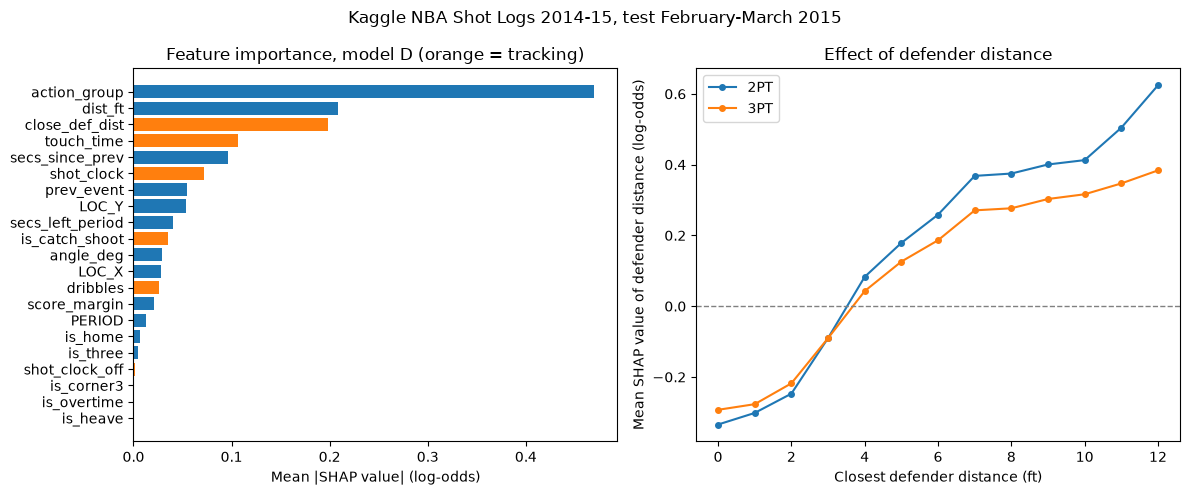

In [4]:
rows_a = {}
for f in ["close_def_dist", "shot_clock", "touch_time", "dribbles", "is_catch_shoot"]:
    feats = GBM_FEATURES + CONTEXT_FEATURES + ([f, "shot_clock_off"] if f == "shot_clock" else [f])
    for i in range(1, len(months)):
        tr, te = df["month"].isin(months[:i]).to_numpy(), (df["month"] == months[i]).to_numpy()
        oos.loc[df.index[te], "B+" + f] = GBMModel(features=feats).fit(df[tr], y[tr]).predict_proba(df[te])[:, 1]
    rows_a["B + " + f] = paired_bootstrap(oos["y"], oos["B+" + f], oos["B_context"], oos["GAME_ID"])
display(pd.DataFrame(rows_a).T.sort_values("diff").round(5))

FEATS = feature_sets["D_context_tracking"]
tr, te = (df["month"] != months[-1]).to_numpy(), (df["month"] == months[-1]).to_numpy()
model = GBMModel(features=FEATS).fit(df[tr], y[tr])
contrib = model.model_.predict(gbm_matrix(df[te], model.categories_, FEATS), pred_contrib=True)
shap = pd.DataFrame(contrib[:, :-1], columns=FEATS, index=df.index[te])
importance = shap.abs().mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ["C1" if f in TRACKING_FEATURES else "C0" for f in importance.index]
axes[0].barh(importance.index, importance.values, color=colors)
axes[0].set(xlabel="Mean |SHAP value| (log-odds)", title="Feature importance, model D (orange = tracking)")
for label, m in [("2PT", df.loc[te, "is_three"] == 0), ("3PT", df.loc[te, "is_three"] == 1)]:
    d = df.loc[te][m]
    g = shap.loc[d.index, "close_def_dist"].groupby(d["close_def_dist"].clip(upper=12).round()).mean()
    axes[1].plot(g.index, g.values, marker="o", ms=4, label=label)
axes[1].axhline(0, color="grey", ls="--", lw=1)
axes[1].set(xlabel="Closest defender distance (ft)", ylabel="Mean SHAP value of defender distance (log-odds)",
            title="Effect of defender distance")
axes[1].legend()
fig.suptitle("Kaggle NBA Shot Logs 2014-15, test February-March 2015")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_kaggle_tracking.pdf")
plt.show()

**Observations.**
- **Tracking features help a lot.** On top of shot + context they lower the log loss by 0.0090 [0.0081; 0.0100]
  (0.6360 -> 0.6270) and raise AUC from 0.667 to 0.681. This is about three times the gain of the play-by-play context
  on the same shots (B − A: −0.0033 [−0.0040; −0.0026]).
- Context and tracking carry partly different information: context still adds −0.0026 on top of tracking (D − C), and
  the full model D is the best in every test month.
- One feature at a time (added to B): defender distance −0.0048, touch time −0.0035, catch-and-shoot −0.0022,
  dribbles −0.0018, shot clock −0.0016, all with CIs below zero. Their sum exceeds the joint gain, so they overlap
  (touch time, dribbles and catch-and-shoot describe the same thing: was the shot created off the dribble).
- In model D defender distance is the third most important feature after shot type and distance. Its effect is
  monotone: about −0.3 log-odds for a defender within 1 ft, zero around 3-4 ft, +0.3 to +0.4 for an open shot (over 6 ft),
  similar for 2PT and 3PT.
- **Answer to RQ1 (defence).** Yes: information about the defence and about how the shot was created is clearly useful,
  and the main model does not have it, because such data are not public after 2016. This is the main limitation of the
  model and of the player analysis: part of what will be measured as *shot making* in Stage 5 is shot difficulty that we
  cannot see (contested vs open shots).
- Caveats: one partial season (October 2014 to March 2015), 93 thousand test shots, default parameters; the level of log
  loss is not comparable with the main model (different season and sample), only the differences between A-D are.